# 01 - Exploratory Data Analysis and Visualisation

**Project:** IEEE-CIS Financial Fraud Detection
**Purpose:** understand the modelling problem before any feature engineering.

## Why this notebook exists

The dataset is a *severe* class-imbalance problem (~3.5 % fraud) with 400+
columns, heavy missingness, and identity data available for only a quarter of
transactions. Each of those properties changes a modelling decision:

| Observation | Design consequence |
|---|---|
| 3.5 % positives | PR-AUC (average precision), not accuracy, is the target metric |
| >80 % missing in 74 columns | drop them; median-impute / label the rest |
| Identity data on ~24 % of rows | left join; missing means "no identity record" |
| `TransactionDT` is seconds, not a date | chronological split, no random k-fold |
| Fraud rate drifts over time | never tune on data later than validation |

Every computation below uses the pipeline's own loaders so the notebook and the
production code cannot silently diverge.


## 1. Environment setup

In [1]:
"""Shared notebook setup: locate the project root, import the pipeline, set plot style."""
from pathlib import Path
import sys, os, warnings

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import PipelineConfig, configure_logging
from src import preprocessing

configure_logging("INFO")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
print("project root:", PROJECT_ROOT)


project root: /Users/dharun/FFDUEAIAEM/financial_fraud_detection


In [2]:
"""Find the raw CSVs.

Resolution order:
1. ``FFDD_DATA_PATH`` environment variable
2. ``<project>/data/raw``
3. a few sibling folders commonly used for the Kaggle export
"""
def locate_data_dir() -> Path:
    candidates = [
        os.environ.get("FFDD_DATA_PATH"),
        PROJECT_ROOT / "data" / "raw",
        PROJECT_ROOT.parent / "Dataset",
        PROJECT_ROOT.parent / "data" / "raw",
        PROJECT_ROOT.parent,
        Path.home() / "Final year project",
        Path.home() / "final year project",
    ]
    for candidate in candidates:
        if not candidate:
            continue
        path = Path(candidate).expanduser()
        if path.is_file():
            path = path.parent
        if path.is_dir() and any("transaction" in p.name.lower() for p in path.glob("*.csv")):
            return path
    raise FileNotFoundError("Set FFDD_DATA_PATH to the folder holding train_transaction.csv")

DATA_DIR = locate_data_dir()
print("data directory:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.glob("*.csv"))[:8])


data directory: /Users/dharun/Final year project
['sample_submission.csv', 'test_identity.csv', 'test_merged.csv', 'test_transaction.csv', 'train_identity.csv', 'train_transaction.csv']


## 2. Load a representative sample

The full table is ~590k rows x 434 columns (~2 GB in memory). For EDA we load
the transaction table and merge identity exactly as the pipeline does, then
optionally subsample for plotting speed. Set `SAMPLE_ROWS = None` to use
everything.

In [3]:
SAMPLE_ROWS = 120_000   # None for the full dataset

config = PipelineConfig(data_path=str(DATA_DIR), project_root=str(PROJECT_ROOT))
transaction_path, identity_path = None, None
for path in sorted(DATA_DIR.glob("*.csv")):
    name = path.name.lower()
    if "transaction" in name and "train" in name:
        transaction_path = path
    elif "identity" in name and "train" in name:
        identity_path = path

raw = preprocessing.load_raw_data(
    config,
    transaction_path=transaction_path,
    identity_path=identity_path,
    load_identity=identity_path is not None,
)
if SAMPLE_ROWS and len(raw) > SAMPLE_ROWS:
    raw = (raw.sample(n=SAMPLE_ROWS, random_state=42)
              .sort_values("TransactionDT").reset_index(drop=True))
    print(f"sampled {len(raw):,} rows")
print(f"shape: {raw.shape}; memory: {raw.memory_usage(deep=True).sum()/1024**2:,.0f} MB")
raw[["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD"]].head()


2026-11-06 14:45:58 | INFO     | src.preprocessing            | Loading transactions from /Users/dharun/Final year project/train_transaction.csv


2026-11-06 14:46:02 | INFO     | src.preprocessing            |   transactions: 590,540 x 394


2026-11-06 14:46:02 | INFO     | src.preprocessing            | Loading identity from /Users/dharun/Final year project/train_identity.csv


2026-11-06 14:46:02 | INFO     | src.preprocessing            |   identity: 144,233 x 41


2026-11-06 14:46:02 | INFO     | src.preprocessing            |   merge: 590,540 rows x 434 cols; 24.4% of transactions have identity data


2026-11-06 14:58:20 | INFO     | src.preprocessing            | reduce_mem_usage: 1984.2 MB -> 617.3 MB (68.9% reduction)


2026-11-06 14:58:20 | INFO     | src.preprocessing            | Loaded raw data in 10.1s


sampled 120,000 rows
shape: (120000, 434); memory: 125 MB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD
0,2987000,0,86400,68.5,W
1,2987002,0,86469,59.0,W
2,2987006,0,86522,159.0,W
3,2987007,0,86529,422.5,W
4,2987012,0,86564,50.0,W


## 3. Class imbalance: the defining constraint

Fraud is rare. A model that predicts "never fraud" scores 96.5 % accuracy while
catching nothing, so accuracy and ROC-AUC are misleading here. This is why the
whole pipeline optimises **PR-AUC** and tunes thresholds against a cost model.

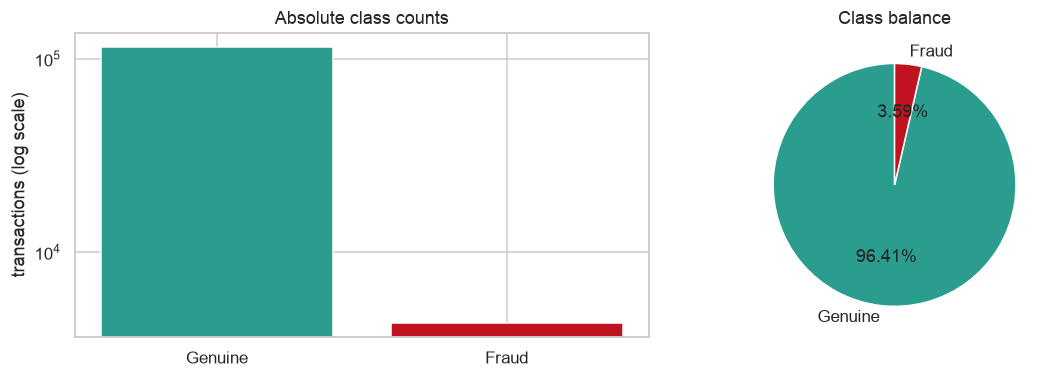

fraud rate: 3.590%
imbalance ratio (neg:pos): 26.9 : 1
suggested scale_pos_weight: 26.86


In [4]:
counts = raw["isFraud"].value_counts().sort_index()
rates = raw["isFraud"].value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(["Genuine", "Fraud"], counts.values, color=["#2a9d8f", "#c1121f"])
axes[0].set_yscale("log")
axes[0].set_ylabel("transactions (log scale)")
axes[0].set_title("Absolute class counts")

axes[1].pie(rates.values, labels=["Genuine", "Fraud"], autopct="%.2f%%",
            colors=["#2a9d8f", "#c1121f"], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Class balance")
fig.tight_layout()
plt.show()

rate = raw["isFraud"].mean()
print(f"fraud rate: {rate:.3%}")
print(f"imbalance ratio (neg:pos): {(1-rate)/rate:.1f} : 1")
print(f"suggested scale_pos_weight: {(1-rate)/rate:.2f}")


## 4. Missing values

74 columns are more than 80 % empty. Keeping them adds noise and memory cost;
the pipeline drops them using statistics from the **training period only** to
avoid leaking information about the future.

In [5]:
missing = raw.isna().mean().sort_values(ascending=False)
print(f"columns >80% missing : {(missing > 0.80).sum():>4}")
print(f"columns >50% missing : {(missing > 0.50).sum():>4}")
print(f"columns with no gaps : {(missing == 0).sum():>4}")
missing.head(15).to_frame("missing_fraction").T.round(3)


columns >80% missing :   24
columns >50% missing :   73
columns with no gaps :  325


,id_27,id_23,id_33,D9,D8,id_30,id_34,V161,V162,V163,V166,V165,V164,V160,V159
missing_fraction,0.991,0.991,0.875,0.872,0.872,0.867,0.867,0.86,0.86,0.86,0.86,0.86,0.86,0.86,0.86


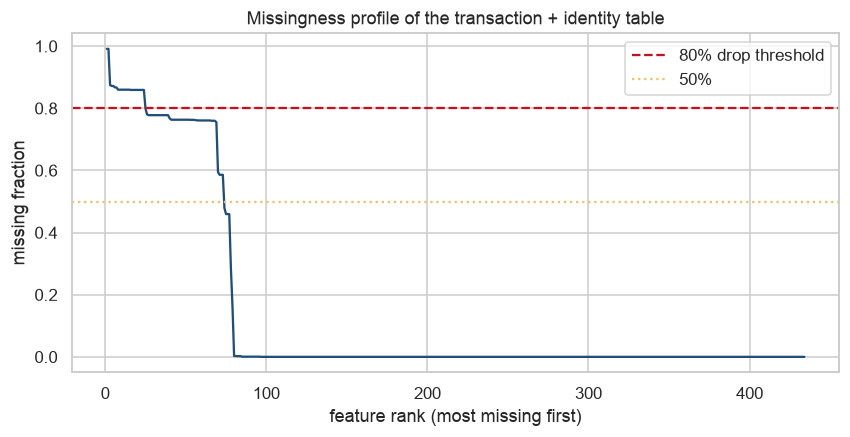

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(missing) + 1), missing.values, color="#1f4e79")
ax.axhline(0.80, color="#c1121f", ls="--", label="80% drop threshold")
ax.axhline(0.50, color="#e9c46a", ls=":", label="50%")
ax.set_xlabel("feature rank (most missing first)")
ax.set_ylabel("missing fraction")
ax.set_title("Missingness profile of the transaction + identity table")
ax.legend()
plt.show()


### Identity data coverage

Only about a quarter of transactions have an identity record (device, browser,
screen resolution). The absence is itself informative: fraudsters often use
fresh devices, so the missingness pattern carries signal.

In [7]:
identity_columns = [c for c in raw.columns if c.startswith("id_")]
if identity_columns:
    has_identity = raw[identity_columns].notna().any(axis=1)
    print(f"identity coverage      : {has_identity.mean():.1%}")
    print(f"fraud rate with id data: {raw.loc[has_identity, 'isFraud'].mean():.2%}")
    print(f"fraud rate without     : {raw.loc[~has_identity, 'isFraud'].mean():.2%}")
else:
    print("identity file not available in this data directory")


identity coverage      : 100.0%
fraud rate with id data: 3.59%
fraud rate without     : nan%


## 5. Transaction amount

Amount is the strongest *interpretable* signal: fraud clusters in unusual amount
bands, and the distribution is heavy-tailed, which is why the pipeline adds
`TransactionAmt_log` and an `amount_cent` feature.

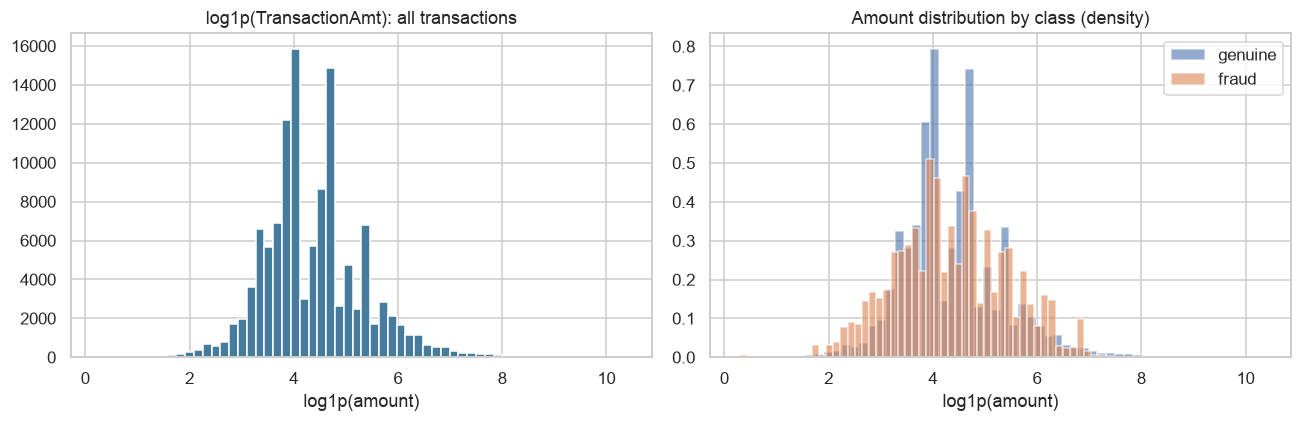

,count,mean,50%,max
isFraud,,,,
0,115692.0,134.67,68.50,31937.39
1,4308.0,141.02,74.14,5191.00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(raw["TransactionAmt"]), bins=60, color="#457b9d")
axes[0].set_title("log1p(TransactionAmt): all transactions")
axes[0].set_xlabel("log1p(amount)")

for label, subset in raw.groupby("isFraud"):
    axes[1].hist(np.log1p(subset["TransactionAmt"]), bins=60, density=True,
                 alpha=0.6, label="fraud" if label == 1 else "genuine")
axes[1].set_title("Amount distribution by class (density)")
axes[1].set_xlabel("log1p(amount)")
axes[1].legend()
fig.tight_layout()
plt.show()

raw.groupby("isFraud")["TransactionAmt"].describe()[["count", "mean", "50%", "max"]].round(2)


## 6. Temporal structure and drift

`TransactionDT` is *seconds elapsed* from an arbitrary reference, spanning about
6 months in train (and a disjoint, later period in test). Fraud rate is not
stationary, which is the core reason for a strictly chronological split.

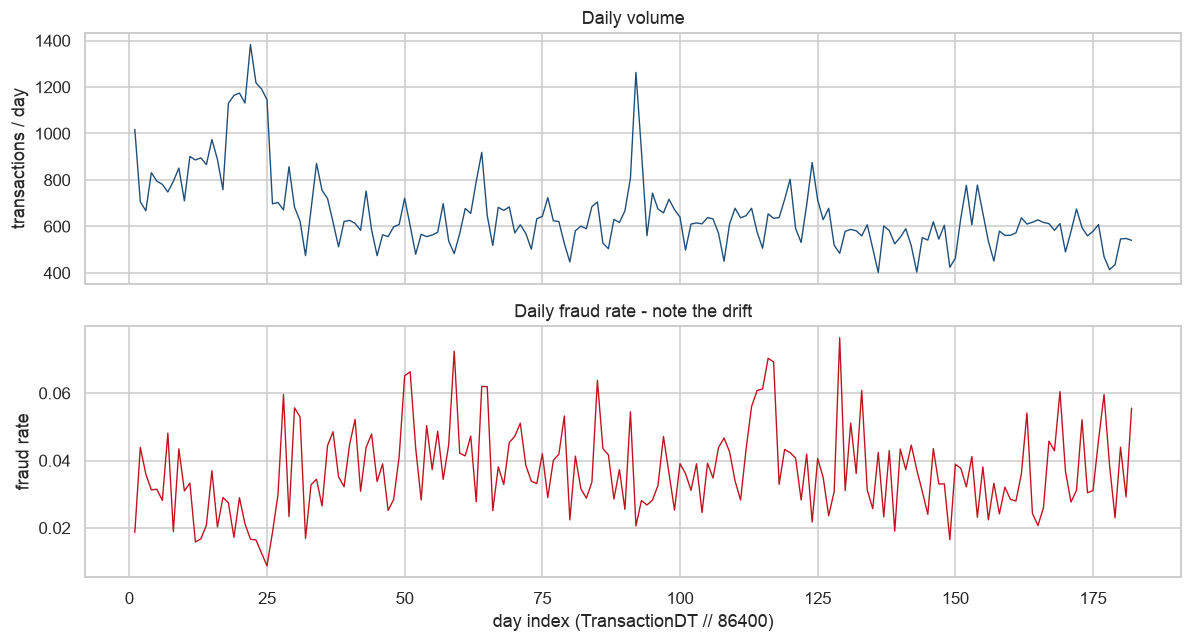

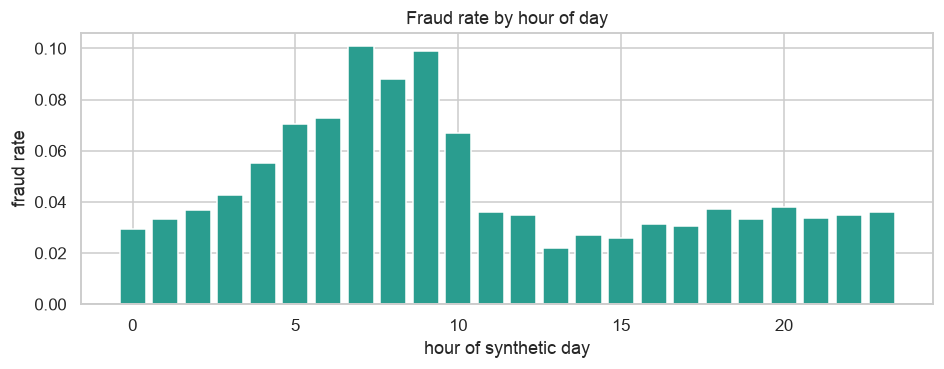

In [9]:
raw["day"] = raw["TransactionDT"] // 86_400
raw["hour"] = (raw["TransactionDT"] % 86_400) // 3_600

daily = raw.groupby("day").agg(transactions=("isFraud", "size"),
                               fraud_rate=("isFraud", "mean"))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily.index, daily["transactions"], color="#1f4e79", lw=0.9)
axes[0].set_ylabel("transactions / day")
axes[0].set_title("Daily volume")
axes[1].plot(daily.index, daily["fraud_rate"], color="#c1121f", lw=0.9)
axes[1].set_ylabel("fraud rate")
axes[1].set_xlabel("day index (TransactionDT // 86400)")
axes[1].set_title("Daily fraud rate - note the drift")
fig.tight_layout()
plt.show()

hourly = raw.groupby("hour")["isFraud"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(hourly.index, hourly["mean"], color="#2a9d8f")
ax.set_xlabel("hour of synthetic day")
ax.set_ylabel("fraud rate")
ax.set_title("Fraud rate by hour of day")
plt.show()


## 7. Categorical signals

`ProductCD`, card network/type and email domains all separate fraud from
legitimate traffic. These become frequency- or target-encoded (fitted on the
training period only) in the pipeline.

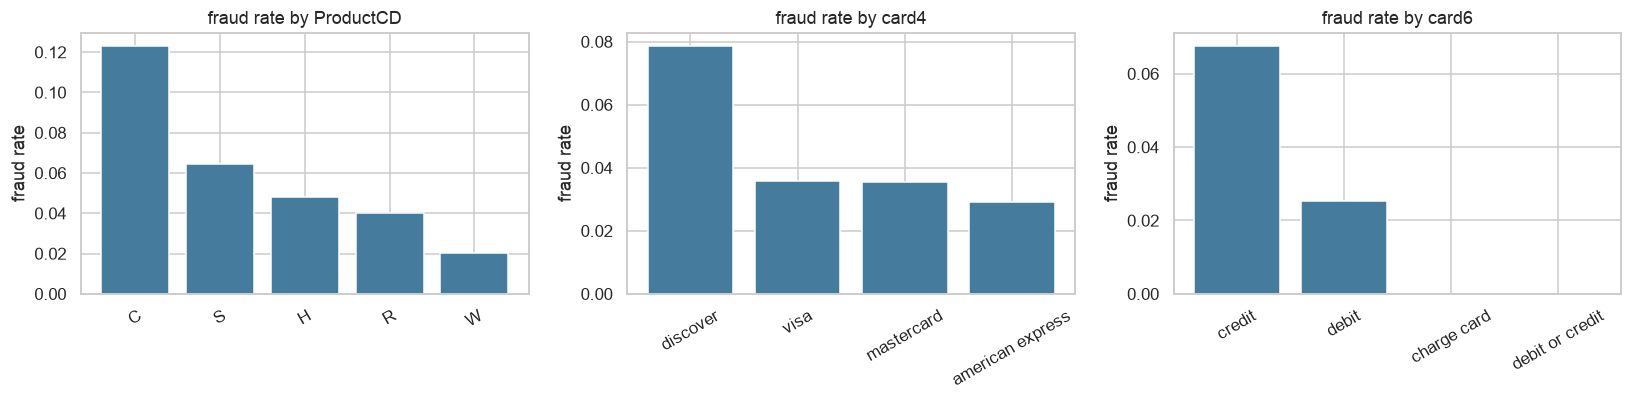

,transactions,fraud_rate,share
ProductCD,,,
C,13791,0.1233,0.1149
S,2457,0.0643,0.0205
H,6764,0.0480,0.0564
R,7681,0.0401,0.0640
W,89307,0.0203,0.7442


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for axis, column in zip(axes, ["ProductCD", "card4", "card6"]):
    stats = (raw.groupby(column)["isFraud"].agg(["mean", "size"])
                .sort_values("mean", ascending=False))
    axis.bar(stats.index.astype(str), stats["mean"], color="#457b9d")
    axis.set_title(f"fraud rate by {column}")
    axis.set_ylabel("fraud rate")
    axis.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

summary = (raw.groupby("ProductCD")["isFraud"]
              .agg(transactions="size", fraud_rate="mean")
              .assign(share=lambda d: d["transactions"] / len(raw))
              .sort_values("fraud_rate", ascending=False))
summary.round(4)


In [11]:
emails = (raw.assign(payer_domain=raw["P_emaildomain"].astype("string").str.split(".").str[0])
             .groupby("payer_domain")["isFraud"]
             .agg(transactions="size", fraud_rate="mean"))
emails = emails[emails["transactions"] >= max(50, int(0.001 * len(raw)))]
emails.sort_values("fraud_rate", ascending=False).head(12).round(4)


,transactions,fraud_rate
payer_domain,,
outlook,1158,0.0933
hotmail,9198,0.0573
gmail,46361,0.0440
icloud,1287,0.0350
live,789,0.0330
comcast,1590,0.0289
msn,838,0.0263
aol,5872,0.0232
anonymous,7556,0.0230


## 8. Which numeric features move with fraud?

A point-biserial correlation against `isFraud` gives a quick, model-free view.
It is a screening tool only - it cannot see interactions, which is why the
pipeline ranks features with TreeSHAP instead.

In [12]:
numeric = raw.select_dtypes(include=[np.number]).drop(columns=["isFraud"], errors="ignore")
correlation = (numeric.corrwith(raw["isFraud"])
                      .dropna()
                      .sort_values(key=np.abs, ascending=False))
print("strongest |correlation| with isFraud:")
correlation.head(20).round(4).to_frame("corr_with_isFraud")


strongest |correlation| with isFraud:


,corr_with_isFraud
D7,0.1697
addr2,-0.1682
addr1,-0.1672
D12,0.1644
D14,0.1581
id_09,0.1526
id_10,0.1525
D6,0.1504
D8,-0.1477
D13,0.1472


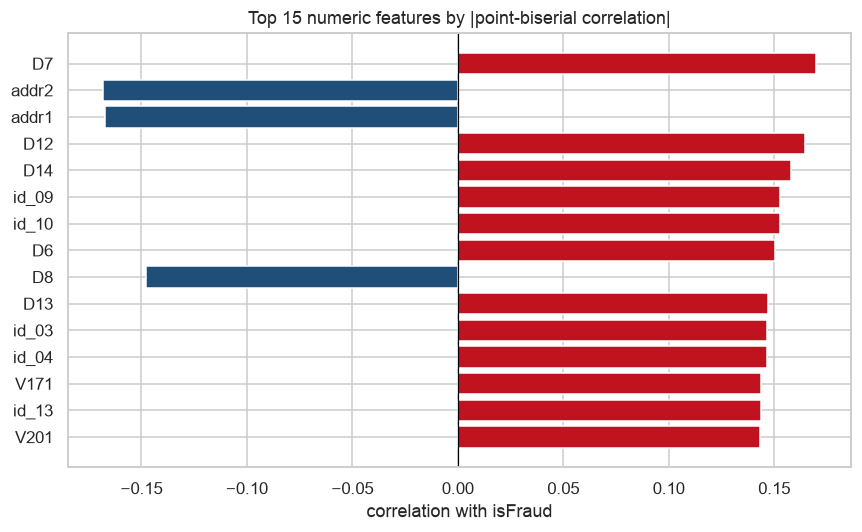

In [13]:
top = correlation.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#c1121f", "#1f4e79"))
ax.set_xlabel("correlation with isFraud")
ax.set_title("Top 15 numeric features by |point-biserial correlation|")
ax.axvline(0, color="black", lw=0.8)
fig.tight_layout()
plt.show()


## 9. Key takeaways for modelling

1. **Imbalance is the constraint** - optimise PR-AUC, not accuracy; always plot
   the PR curve against the no-skill baseline.
2. **Drift is real** - the daily fraud rate moves, so a chronological split (and
   `TimeSeriesSplit` inside the training period) is mandatory.
3. **Missingness is structured** - drop the >80 % columns, but keep the
   "no identity record" signal rather than discarding identity rows.
4. **Amount and email domains** are the most interpretable fraud tells; the
   `C*` count and `D*` timedelta blocks dominate the SHAP ranking.
5. **Train and test are disjoint periods**, so time-dependent features must be
   handled carefully - raw `TransactionDT` is kept only as a coarse continuous
   indicator.

The next notebook (`02_model_prototyping.ipynb`) turns these observations into a
model comparison using the pipeline modules.
